# Step 1 - Understand the data
- Identify the input features X and the target y.
- Explain what class 0 and class 1 mean.
- Check the number and proportion of observations in each class.
- Choose three features of different types and briefly explain what their values mean. Use the Understanding the Dataset guide.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.max_columns", 100)

df = pd.read_csv("../data/diabetes_binary_classification_data.csv")

print(f"rows: {df.shape[0]:,}   columns: {df.shape[1]}")
df.head()

rows: 253,680   columns: 22


,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,HvyAlcoholConsump,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


In [2]:
X = df.drop(columns=["Diabetes_binary"])
y = df["Diabetes_binary"]

print(f"{X.shape[1]} input features:", list(X.columns))
pd.DataFrame({
    "count": y.value_counts(),
    "proportion": y.value_counts(normalize=True).round(3),
})

21 input features: ['HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income']


,count,proportion
Diabetes_binary,,
0.0,218334,0.861
1.0,35346,0.139


In [3]:
# Exact duplicate rows (all 22 columns identical)
print(f"Duplicate rows: {df.duplicated().sum():,}")
print(f"Missing values: {df.isna().sum().sum()}")

Duplicate rows: 24,206
Missing values: 0


**Input features and target.** The target `y` is `Diabetes_binary`. The 21 remaining columns are the input features `X`.

**Classes.** Class 0 means the respondent has no diabetes. Class 1 means prediabetes or diabetes.

**Class balance.** The target is clearly imbalanced: 218,334 rows (86.1 %) are class 0 and only 35,346 (13.9 %) are class 1. A model that always predicts 0 would already reach 86 % accuracy, so accuracy alone will be misleading when we evaluate the model.

**Three features of different types:**
- **BMI (numerical):** body mass index in kg/m² (12–98). Higher means more weight relative to height.
- **HighBP (binary categorical):** 0 = never told they have high blood pressure, 1 = told they have high blood pressure.
- **GenHlth (ordered categorical):** self-rated general health, 1 = excellent, 2 = very good, 3 = good, 4 = fair, 5 = poor. The codes have an order, but 5 is not "five times" 1.

**Data quality.** There are no missing values, but 24,206 rows are exact duplicates of another row (see the cell above). With only 21 coded survey answers, different people can easily give identical answers, so we keep them. They can, however, end up in both TRAIN and TEST.

All values are stored as floats in the CSV, so the codebook is needed to know whether a column is a measurement, a yes/no flag or an ordered category code.

In [4]:
corr_series = df.corr()['Diabetes_binary'].abs()
corr_series[corr_series < 0.1].sort_values(ascending=False)

MentHlth             0.069315
CholCheck            0.064761
Smoker               0.060789
HvyAlcoholConsump    0.057056
Veggies              0.056584
Fruits               0.040779
NoDocbcCost          0.031433
Sex                  0.031430
AnyHealthcare        0.016255
Name: Diabetes_binary, dtype: float64

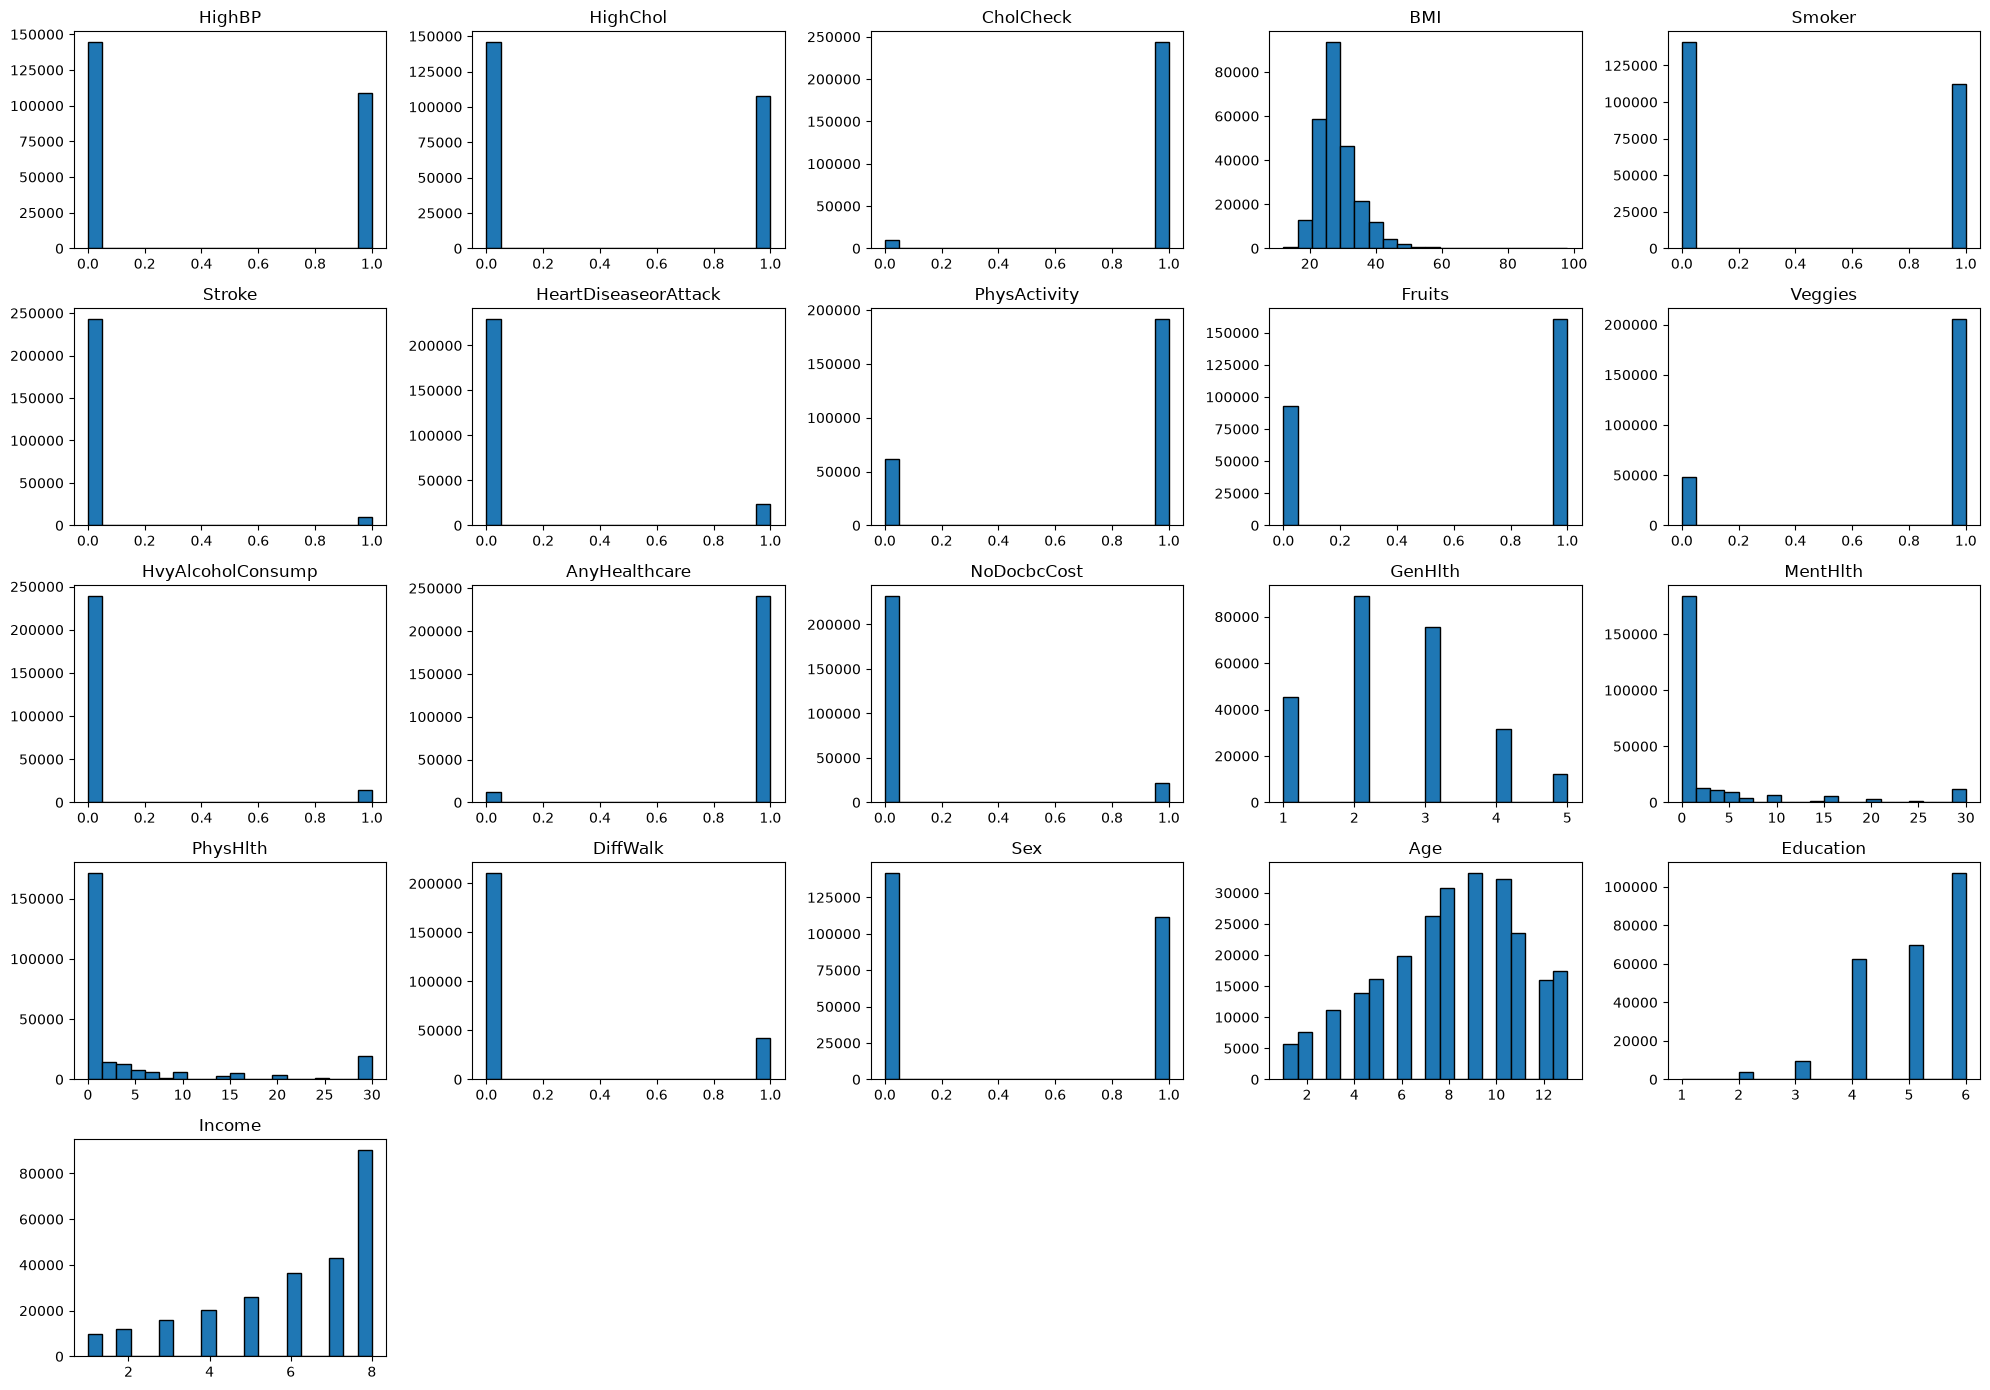

In [5]:
X.hist(bins=20, figsize=(20, 14), grid=False, edgecolor='black');
plt.tight_layout()
plt.show()

# Step 2 - Explore the data
Use EDA to investigate all input features and their relationships with Diabetes_binary. Choose plots or tables that are appropriate
for each type of feature:
- for numerical features, examine their distributions and compare them between the two target classes;
- for binary categorical features, examine counts/proportions and compare the proportion of Diabetes_binary across the two
categories;
- for ordered categorical features, examine how the distribution or proportion of Diabetes_binary changes across the ordered
categories.

Explore all input features, but focus your detailed interpretation on the most informative or interesting results. You may use loops
or functions where appropriate rather than repeating essentially identical code. For the results you discuss in detail, state the
question, show appropriate evidence, explain what you observe, and explain what the evidence allows you to conclude and what it
does not. Look for patterns such as differences between the two target classes, changes in the proportion of class 1 across
categories, unusual distributions, and features that appear to have little relationship with the target. Remember: EDA describes
associations and patterns in the observed data; an association does not show that one variable causes diabetes.

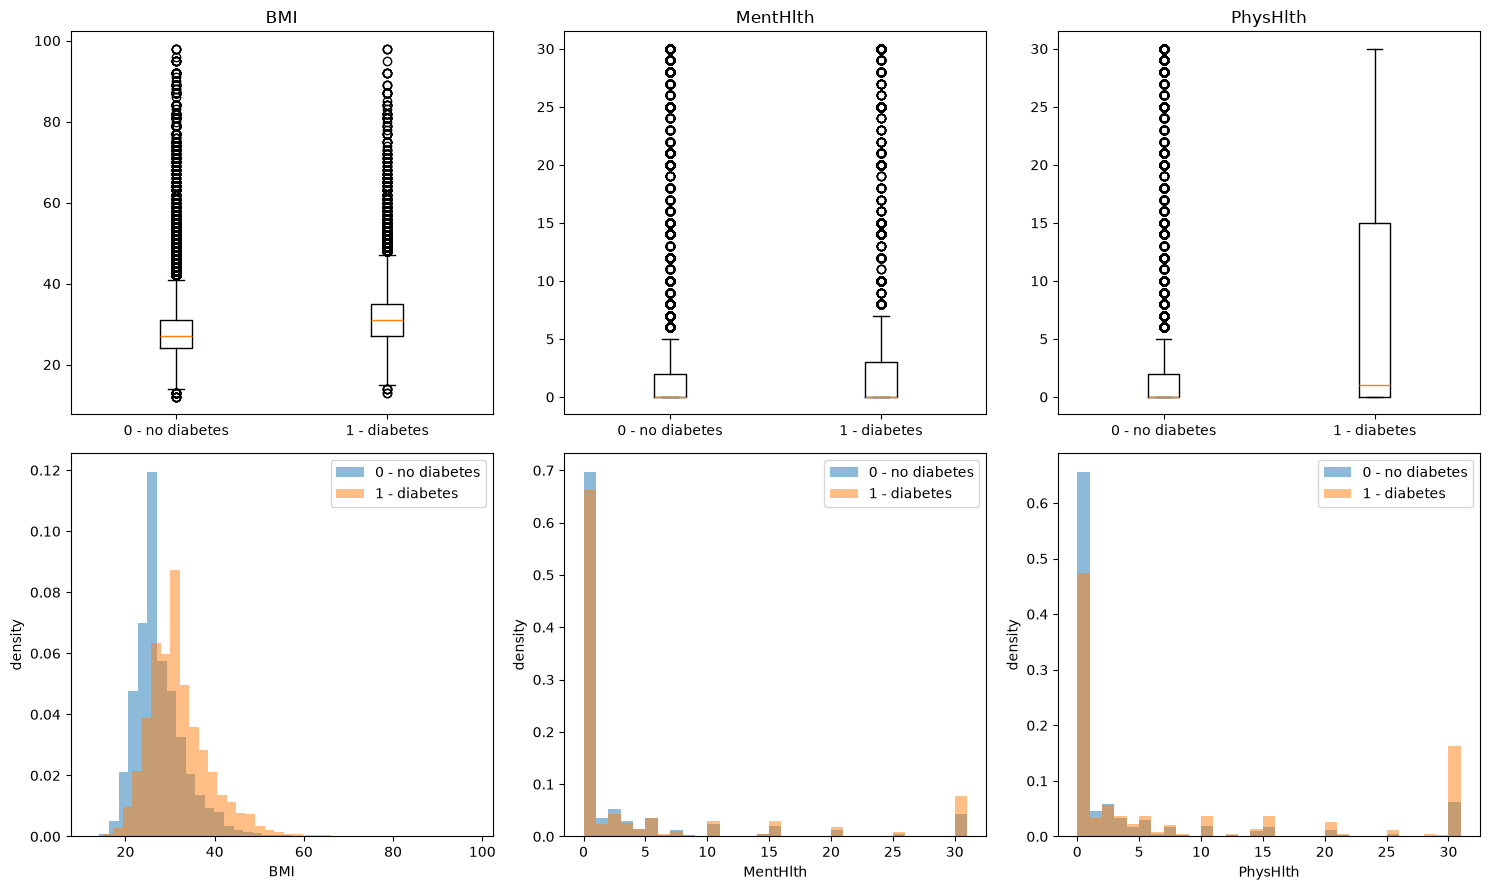

In [6]:
numerical_features = ["BMI", "MentHlth", "PhysHlth"]

fig, ax = plt.subplots(2, len(numerical_features), figsize=(15, 9))

for i, col in enumerate(numerical_features):
    no_diabetes = df.loc[df["Diabetes_binary"] == 0, col]
    diabetes = df.loc[df["Diabetes_binary"] == 1, col]

    # Top row: boxplots per class
    ax[0, i].boxplot([no_diabetes, diabetes], tick_labels=["0 - no diabetes", "1 - diabetes"])
    ax[0, i].set_title(col)

    # Bottom row: histograms per class, normalised so the classes are comparable
    bins = np.arange(df[col].min(), df[col].max() + 2) if col != "BMI" else 40
    ax[1, i].hist(no_diabetes, bins=bins, density=True, alpha=0.5, label="0 - no diabetes")
    ax[1, i].hist(diabetes, bins=bins, density=True, alpha=0.5, label="1 - diabetes")
    ax[1, i].set_xlabel(col)
    ax[1, i].set_ylabel("density")
    ax[1, i].legend()

plt.tight_layout()
plt.show()

In [7]:
df.groupby("Diabetes_binary")[numerical_features].agg(["mean", "median"]).round(2)

BMI        MentHlth        PhysHlth       
                  mean median     mean median     mean median
Diabetes_binary                                              
0.0              27.81   27.0     2.98    0.0     3.64    0.0
1.0              31.94   31.0     4.46    0.0     7.95    1.0

In [8]:
# Share of rows at 0 days for the "days" features, and share of very high BMI values
print("Share of rows with 0 days:", (df[["MentHlth", "PhysHlth"]] == 0).mean().round(3).to_dict())
print(f"Share of rows with BMI > 50: {(df['BMI'] > 50).mean():.3%}")

Share of rows with 0 days: {'MentHlth': 0.693, 'PhysHlth': 0.631}
Share of rows with BMI > 50: 0.857%


**Question:** do BMI, MentHlth and PhysHlth differ between people with and without diabetes?

**Observations.**
- **BMI** is shifted upwards for class 1: median 31 against 27 for class 0. Both classes have long right tails with a few extreme values (up to 98), which are probably partly reporting errors.
- **MentHlth** and **PhysHlth** (days of poor mental/physical health in the last 30 days) are heavily concentrated at 0 days (69 % and 63 % of rows, see the table above). Only 0.9 % of rows have BMI above 50. PhysHlth differs clearly between the classes (mean 7.9 vs 3.6 days), MentHlth much less (4.5 vs 3.0 days).

**Decision:** keep all three as numerical features and standardise them, because they are on very different scales (BMI 12–98, days 0–30). We keep the extreme BMI values: they are few, and we cannot tell which of them are reporting errors.

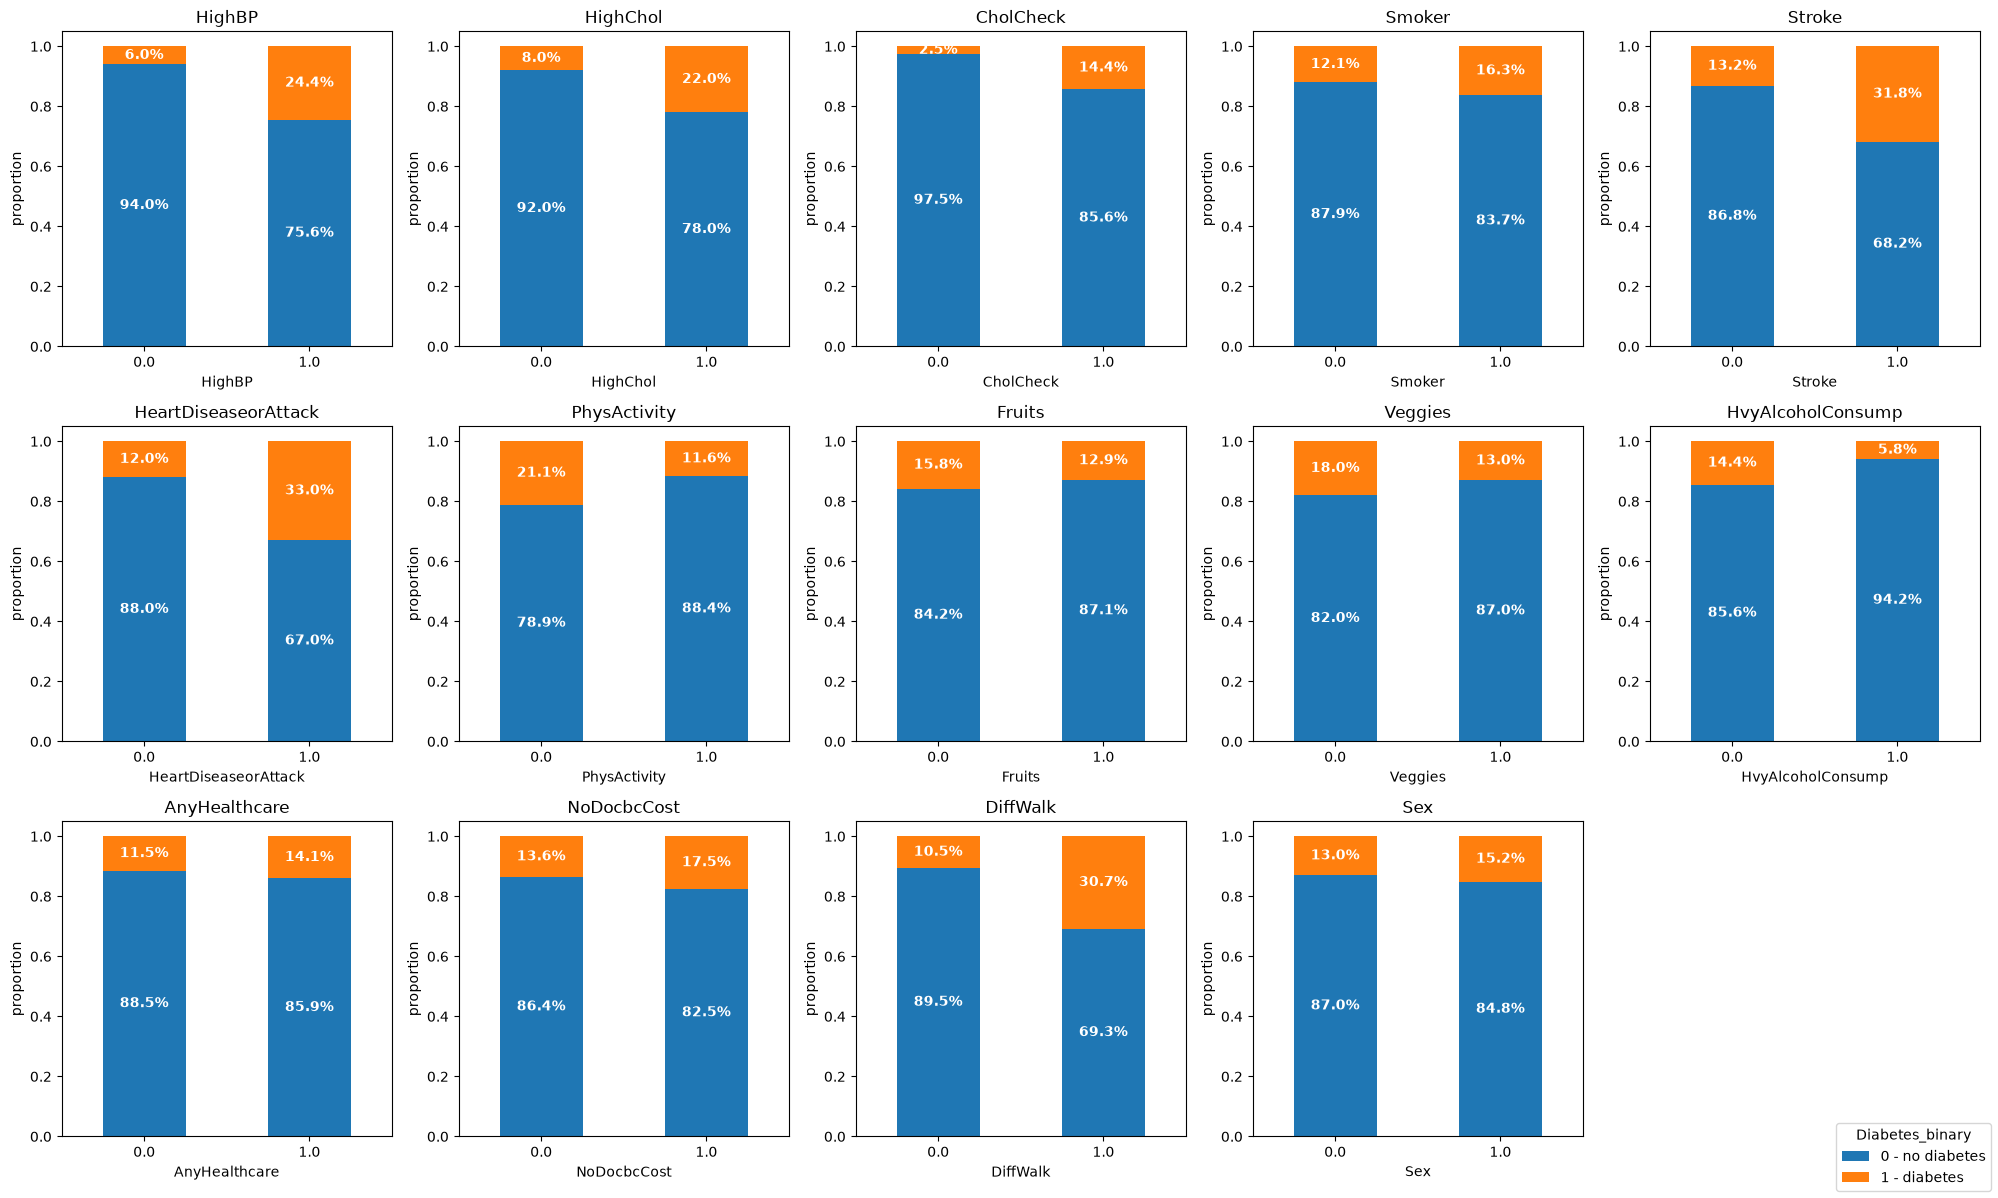

In [9]:
binary_features = [
    "HighBP",
    "HighChol",
    "CholCheck",
    "Smoker",
    "Stroke",
    "HeartDiseaseorAttack",
    "PhysActivity",
    "Fruits",
    "Veggies",
    "HvyAlcoholConsump",
    "AnyHealthcare",
    "NoDocbcCost",
    "DiffWalk",
    "Sex"
]
class_labels = ["0 - no diabetes", "1 - diabetes"]

fig, ax = plt.subplots(3, 5, figsize=(20, 12))

for a, col in zip(ax.flat, binary_features):

    # 1. Normalize by index so each column bar sums to 1.0 (100%)
    ct = pd.crosstab(df[col], df["Diabetes_binary"], normalize="index")
    ct.columns = class_labels

    # 2. Plot the stacked bar
    ct.plot(kind="bar", stacked=True, ax=a, legend=False, rot=0)
    a.set_title(col)
    a.set_ylabel("proportion")

    # 3. Loop through bars to add percentage text labels
    for container in a.containers:
        # Get labels formatted as percentages (e.g., 45.2%)
        # Only display the label if the bar segment height is greater than 0
        labels = [f"{v.get_height()*100:.1f}%" if v.get_height() > 0 else '' for v in container]

        # Center the text inside each bar segment
        a.bar_label(container, labels=labels, label_type="center", color="white", fontweight="bold")

# Hide the unused subplot and show one shared legend
ax.flat[-1].axis("off")
handles, labels = ax.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower right", title="Diabetes_binary")
plt.tight_layout()
plt.show()

**Question:** how does the proportion of class 1 differ between the two categories of each binary feature?

**Observations.** The share of class 1 is much higher when the person has:
- HighBP: 24 % vs 6 %
- HighChol: 22 % vs 8 %
- DiffWalk: 31 % vs 11 %
- HeartDiseaseorAttack: 33 % vs 12 %
- Stroke: 32 % vs 13 %

PhysActivity and HvyAlcoholConsump go in the opposite direction: 12 % vs 21 % and 6 % vs 14 %. Smoker, Fruits, Veggies, AnyHealthcare, NoDocbcCost and Sex change the share only a few percentage points, which matches their low correlation with the target (|r| < 0.07, see the correlation table in Step 1). CholCheck is extremely unbalanced (96 % answered yes), so the "no" group is small.

**Decision:** keep all binary features as they are (0/1, no scaling). We also keep the weak ones: EDA looks at one feature at a time, and Logistic Regression can give a feature a small weight if it does not help. The four chronic conditions (HighBP, HighChol, Stroke, HeartDiseaseorAttack) all show a clear difference, which is why we test a combined `ChronicCount` feature in the workflow notebook.

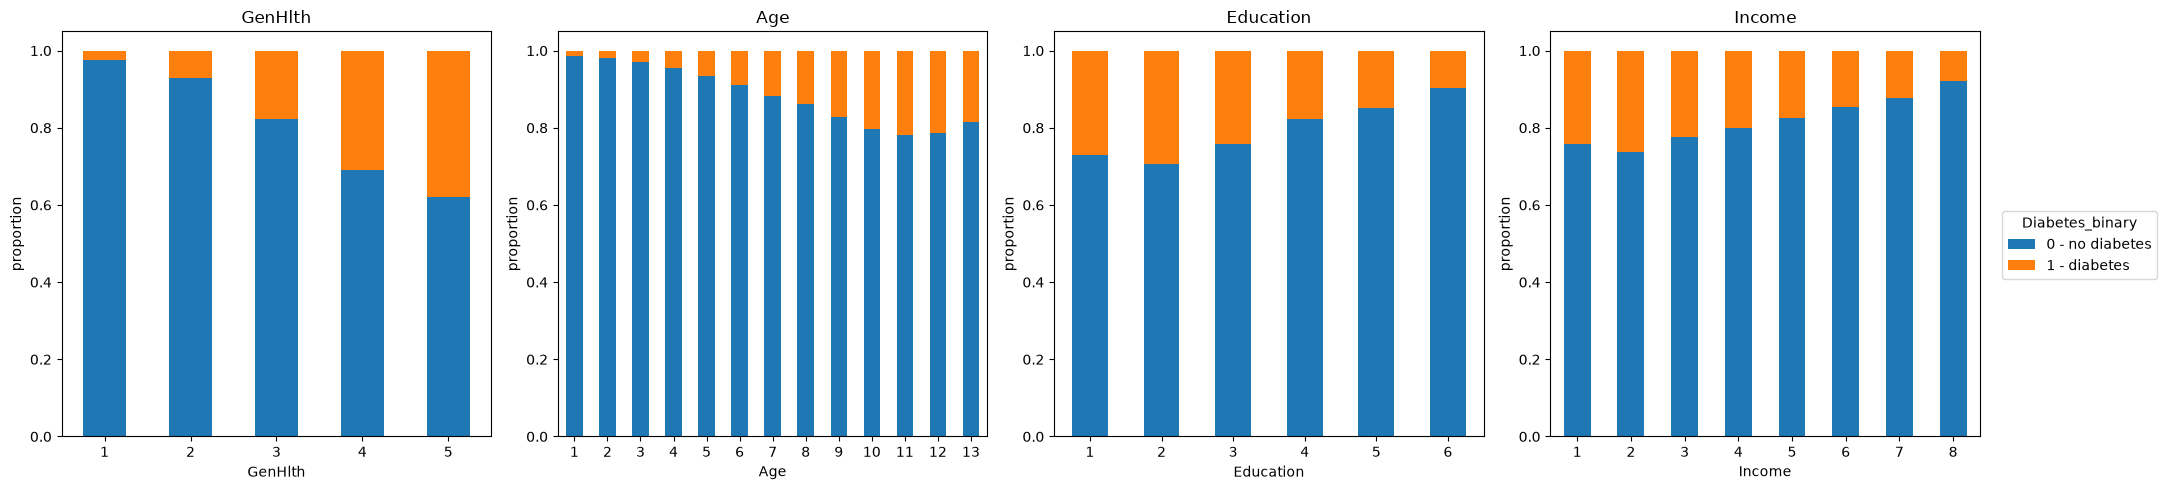

In [10]:
ordinal_features = ["GenHlth", "Age", "Education", "Income"]

fig, ax = plt.subplots(1, len(ordinal_features), figsize=(5*len(ordinal_features), 5))

for a, col in zip(ax, ordinal_features):
    ct = pd.crosstab(df[col], df['Diabetes_binary'], normalize='index')
    ct.columns = class_labels
    ct.index = ct.index.astype(int)

    ct.plot(kind='bar', stacked=True, ax=a, legend=False, rot=0)
    a.set_title(col)
    a.set_ylabel("proportion")

handles, labels = ax[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="center left", bbox_to_anchor=(1.0, 0.5), title="Diabetes_binary")
plt.tight_layout()
plt.show()

In [11]:
# Proportion of class 1 within each category of the ordered features
for col in ordinal_features:
    print(col, (df.groupby(col)["Diabetes_binary"].mean() * 100).round(1).to_dict())

GenHlth {1.0: 2.5, 2.0: 7.2, 3.0: 17.8, 4.0: 31.0, 5.0: 37.9}
Age {1.0: 1.4, 2.0: 1.8, 3.0: 2.8, 4.0: 4.5, 5.0: 6.5, 6.0: 8.8, 7.0: 11.7, 8.0: 13.8, 9.0: 17.2, 10.0: 20.4, 11.0: 21.8, 12.0: 21.3, 13.0: 18.5}
Education {1.0: 27.0, 2.0: 29.3, 3.0: 24.2, 4.0: 17.6, 5.0: 14.8, 6.0: 9.7}
Income {1.0: 24.3, 2.0: 26.2, 3.0: 22.3, 4.0: 20.1, 5.0: 17.4, 6.0: 14.5, 7.0: 12.2, 8.0: 8.0}


**Question:** how does the proportion of class 1 change across the ordered categories?

**Observations.**
- **GenHlth:** the share of class 1 rises steadily from 2.5 % (excellent) to 37.9 % (poor). This is the clearest gradient in the data.
- **Age:** the share rises from 1.4 % in the youngest group (18–24) to about 22 % at ages 70–79, then drops slightly to 18.5 % for 80+.
- **Education and Income:** the share falls as education and income increase, from about 24–29 % in the lowest groups to 8–10 % in the highest.

**Decision:** keep the ordered features as their integer codes (standardised) instead of one-hot encoding, because the share of class 1 changes mostly in one direction across the categories. This does assume roughly equal steps between categories, which is not quite true for Age (the share drops again for 80+) or for the lowest Education levels. We list this as a limitation.

## Summary of the EDA
**Most informative findings:** general health, age, high blood pressure and cholesterol, BMI and income/education all show clear differences in the share of diabetes.

**What we can conclude:** in this survey these features are *associated* with diabetes and are likely to be useful predictors.

**What we cannot conclude:** that any feature *causes* diabetes. The data is self-reported and cross-sectional, so there is no time order. The direction may be reversed (diabetes can make people rate their health as poor), and confounders such as age affect several features at once.